# 📉 Customer Churn Analysis & Retention Intelligence

**An end-to-end churn analytics pipeline for a subscription (OTT-style) business**, built with SQL + Python.

This project identifies **who is churning, why, and when**, quantifies the **revenue at risk**, and turns the
findings into **actionable retention recommendations** for the business.

| | |
|---|---|
| **Domain** | Subscription / OTT streaming (patterns apply to SaaS, E-commerce, Fintech, Telecom) |
| **Tech stack** | Python, SQL (SQLite), pandas, numpy, matplotlib, seaborn |
| **Data** | 3 relational tables — customers, subscriptions, support tickets |
| **Skills demonstrated** | SQL ↔ Python integration, data cleaning, feature engineering, EDA, data visualization, business storytelling |

---


## 1. Business Context

Churn analysis is the process of understanding **why customers stop doing business with you**. Every retention
strategy starts by answering three questions:

- **Who** — which customers have already left, or are likely to leave soon?
- **Why** — what behavioral or service signals precede a cancellation?
- **When** — is there a "danger zone" (a point in the customer journey) where churn risk spikes?

For a subscription business, churn is defined as: **the subscription's `cancellation_date` is populated** (i.e. the
customer actively cancelled).


## 2. Setup — Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 3. Data Extraction — SQL → Python

The raw data lives in a relational SQLite database (`customer_churn.db`) with three tables:

| Table | Grain | Key columns |
|---|---|---|
| `db_customer` | 1 row / customer | demographics (name, country, state, gender, dob) |
| `db_subscription` | 1 row / customer | plan, contract, charges, cancellation info, churn_score |
| `db_support` | 1 row / support ticket | complaint date, escalation flag, CSAT score |

> If `customer_churn.db` is not available, the cell below rebuilds it from the raw Excel workbook
> (`customer_churn_data_raw.xlsx`) so the notebook always runs end-to-end.


In [2]:
import os

DB_PATH = '/home/claude/churn_project/customer_churn.db'
EXCEL_PATH = '/home/claude/churn_project/customer_churn_data_raw.xlsx'

if not os.path.exists(DB_PATH):
    conn = sqlite3.connect(DB_PATH)
    excel_data = pd.ExcelFile(EXCEL_PATH)
    for sheet in excel_data.sheet_names:
        pd.read_excel(EXCEL_PATH, sheet_name=sheet).to_sql(
            name=sheet, con=conn, if_exists="replace", index=False
        )
    conn.close()
    print("Database rebuilt from Excel source.")
else:
    print("Using existing SQLite database:", DB_PATH)

Using existing SQLite database: /home/claude/churn_project/customer_churn.db


In [3]:
# Connect to the database and dynamically load every table into its own DataFrame
conn = sqlite3.connect(DB_PATH)

tables = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table';", conn
)

for table_name in tables["name"]:
    globals()[f"df_{table_name}"] = pd.read_sql(f"SELECT * FROM {table_name}", conn)
    print(f"Loaded df_{table_name}  ->  shape {globals()[f'df_{table_name}'].shape}")

conn.close()

Loaded df_db_customer  ->  shape (21, 8)
Loaded df_db_subscription  ->  shape (21, 11)
Loaded df_db_support  ->  shape (9, 6)


In [4]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [5]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [6]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


## 4. Data Cleaning

Each table is cleaned independently before joining, following a standard checklist:
renaming, dropping unused columns, correcting data types, standardizing categorical values,
and filling missing values using logic derived from the data itself.


### 4.1 Customer table

In [7]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [8]:
# a. Rename column for clarity
df_db_customer = df_db_customer.rename(columns={"name": "customer_name"})

# b. Drop columns not needed for churn analysis
df_db_customer = df_db_customer.drop(columns=["interests", "pincode"])

# c. Fix data type
df_db_customer["dob"] = pd.to_datetime(df_db_customer["dob"])

# d. Standardize categorical values
df_db_customer["gender"] = df_db_customer["gender"].replace({"Men": "Male", "Women": "Female"})

# e. Fill missing `country` using the state -> country mapping learned from complete rows
state_country_map = (
    df_db_customer.dropna(subset=["country"]).set_index("state")["country"].to_dict()
)
df_db_customer["country"] = df_db_customer["country"].fillna(
    df_db_customer["state"].map(state_country_map)
)

print("Missing values remaining:\n", df_db_customer.isna().sum())

Missing values remaining:
 customerid       0
customer_name    0
country          0
state            0
gender           0
dob              0
dtype: int64


### 4.2 Subscription table

In [9]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [10]:
date_cols = ["subscription_start_date", "renewal_date", "cancellation_date"]
df_db_subscription[date_cols] = df_db_subscription[date_cols].apply(pd.to_datetime)

# A customer has churned if they have a cancellation date
df_db_subscription["churn_flag"] = np.where(
    df_db_subscription["cancellation_date"].notna(), 1, 0
)

df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


### 4.3 Support table

In [11]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [12]:
# Drop unused / empty columns
df_db_support = df_db_support.drop(columns=["col_1", "comment"])
df_db_support["complaint_date"] = pd.to_datetime(df_db_support["complaint_date"])

# A customer can have multiple support tickets -> capture total complaint count,
# then collapse to one row per customer (their most recent ticket) before joining.
df_db_support["complaint_count"] = df_db_support.groupby("customerid")["customerid"].transform("count")
df_db_support = df_db_support.sort_values("complaint_date").drop_duplicates("customerid", keep="last")

df_db_support.head()

,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1


## 5. Feature Engineering & Joining the Tables

We join `subscription` (grain of analysis) with `customer` and `support` on `customerid`,
then engineer the features needed for churn analysis: tenure, churn risk tier, and numeric
encodings for escalations.


In [13]:
df = (
    df_db_subscription
    .merge(df_db_customer, on="customerid", how="left")
    .merge(df_db_support, on="customerid", how="left")
)

print("Subscription rows:", df_db_subscription.shape[0], " -> Merged rows:", df.shape[0])
df.shape

Subscription rows: 21  -> Merged rows: 21


(21, 21)

In [14]:
# Customer tenure in days: cancellation_date if churned, else "today"
today = pd.Timestamp.today()

df["tenure_days"] = np.where(
    df["cancellation_date"].notna(),
    (df["cancellation_date"] - df["subscription_start_date"]).dt.days,
    (today - df["subscription_start_date"]).dt.days,
)

# Churn risk tier from the pre-computed churn_score (0-100)
risk_conditions = [
    df["churn_score"] < 50,
    (df["churn_score"] >= 50) & (df["churn_score"] < 70),
    df["churn_score"] >= 70,
]
risk_choices = ["Low", "Medium", "High"]
df["churn_risk"] = np.select(risk_conditions, risk_choices, default="Unknown")

# Numeric encoding of escalations (Y/N -> 1/0) for correlation analysis
df["escalation_flag"] = np.where(df["escalations"] == "Y", 1, 0)

df[["customerid", "plan_type", "contract_type", "tenure_days", "churn_flag", "churn_risk"]].head()

,customerid,plan_type,contract_type,tenure_days,churn_flag,churn_risk
0,0002-ORFBO,Standard,Annual,1962.0,0,Low
1,0003-MKNFE,Premium,Annual,1501.0,1,High
2,0004-TLHLJ,Basic,Monthly,1347.0,0,Low
3,0011-IGKFF,Premium,Annual,2637.0,0,Low
4,0013-EXCHZ,Standard,Monthly,419.0,1,High


In [15]:
# Export the cleaned, merged, analysis-ready dataset
df.to_csv("exported_churn_data.csv", index=False)
print("Exported: exported_churn_data.csv  ", df.shape)

Exported: exported_churn_data.csv   (21, 24)


## 6. KPI Calculations

Core churn KPIs, calculated directly from the merged dataset.


In [16]:
churn_rate = df["churn_flag"].mean() * 100
retention_rate = 100 - churn_rate

print(f"Churn Rate      = {churn_rate:.2f}%")
print(f"Retention Rate  = {retention_rate:.2f}%")

Churn Rate      = 28.57%
Retention Rate  = 71.43%


In [17]:
churn_by_plan = (
    df.groupby("plan_type")["churn_flag"].mean().mul(100).round(2)
    .sort_values(ascending=False).reset_index(name="churn_rate_pct")
)
churn_by_plan

,plan_type,churn_rate_pct
0,Basic,60.00
1,Standard,22.22
2,Premium,14.29


In [18]:
churn_by_contract = (
    df.groupby("contract_type")["churn_flag"].mean().mul(100).round(2)
    .sort_values(ascending=False).reset_index(name="churn_rate_pct")
)
churn_by_contract

,contract_type,churn_rate_pct
0,Monthly,55.56
1,Annual,8.33


In [19]:
churn_by_state = (
    df.groupby("state")["churn_flag"].mean().mul(100).round(2)
    .sort_values(ascending=False).reset_index(name="churn_rate_pct")
)
churn_by_state

,state,churn_rate_pct
0,Karnataka,100.00
1,Meghalaya,66.67
2,Telangana,50.00
3,Delhi,25.00
4,Kathmandu,0.00
5,Maharashtra,0.00
6,Nagaland,0.00
7,Rajasthan,0.00
8,Uttar Pradesh,0.00


In [20]:
arpu = df["monthly_charges"].mean()
avg_tenure = df["tenure_days"].mean()

print(f"ARPU (Avg Revenue Per User)  = {arpu:.2f}")
print(f"Average Customer Tenure      = {avg_tenure:.0f} days (~{avg_tenure/365:.1f} years)")

ARPU (Avg Revenue Per User)  = 18.85
Average Customer Tenure      = 1505 days (~4.1 years)


In [21]:
total_revenue = df["monthly_charges"].sum()
revenue_at_risk = df.loc[df["churn_flag"] == 1, "monthly_charges"].sum()
pct_revenue_loss = revenue_at_risk / total_revenue * 100
cltv_lost = df.loc[df["churn_flag"] == 1, "cltv"].sum()

print(f"Total Monthly Revenue (book) = {total_revenue:.2f}")
print(f"Revenue at Risk (churned)    = {revenue_at_risk:.2f}  ({pct_revenue_loss:.1f}% of total)")
print(f"CLTV Lost to Churn           = {cltv_lost:.0f}")

Total Monthly Revenue (book) = 395.79
Revenue at Risk (churned)    = 73.94  (18.7% of total)
CLTV Lost to Churn           = 2047


In [22]:
escalation_rate = (df["escalations"] == "Y").mean() * 100
avg_complaints_per_user = df["complaint_count"].fillna(0).sum() / df["customerid"].nunique()
esc_churn_corr = df[["escalation_flag", "churn_flag"]].corr().iloc[0, 1]

print(f"Escalation Rate                    = {escalation_rate:.2f}%")
print(f"Avg Complaints per Customer         = {avg_complaints_per_user:.2f}")
print(f"Correlation (escalation vs. churn)  = {esc_churn_corr:.2f}")

Escalation Rate                    = 19.05%
Avg Complaints per Customer         = 0.43
Correlation (escalation vs. churn)  = 0.77


In [23]:
df["churn_risk"].value_counts().rename_axis("churn_risk").reset_index(name="customers")

,churn_risk,customers
0,Low,13
1,High,6
2,Medium,2


## 7. Data Visualization

### 7.1 Matplotlib — trend & comparison charts


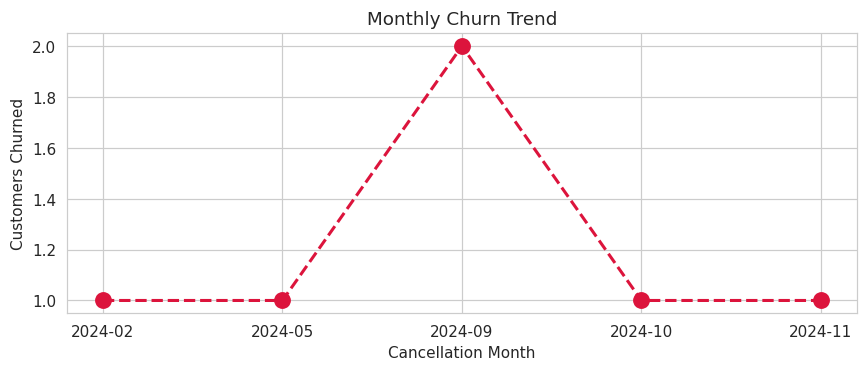

In [24]:
monthly_churn = (
    df[df["churn_flag"] == 1]
    .assign(cancellation_month=lambda d: d["cancellation_date"].dt.to_period("M").astype(str))
    .groupby("cancellation_month").size()
)

plt.figure(figsize=(8, 3.5))
plt.plot(monthly_churn.index, monthly_churn.values, color="crimson",
         marker="o", linestyle="--", linewidth=2, markersize=10)
plt.title("Monthly Churn Trend")
plt.xlabel("Cancellation Month")
plt.ylabel("Customers Churned")
plt.tight_layout()
plt.show()

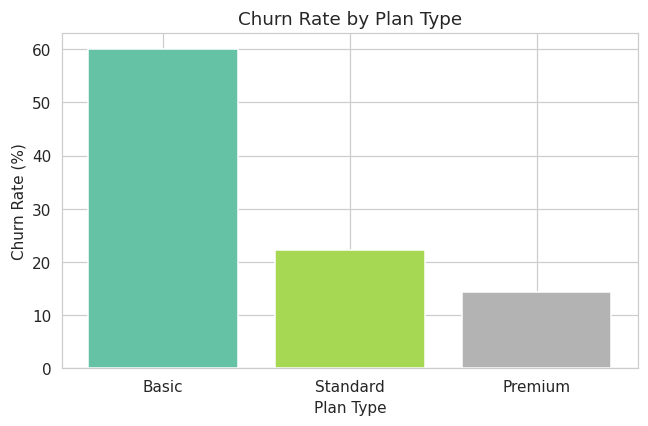

In [25]:
plan_order = churn_by_plan.sort_values("churn_rate_pct", ascending=False)

plt.figure(figsize=(6, 4))
colors = plt.cm.Set2(np.linspace(0, 1, len(plan_order)))
plt.bar(plan_order["plan_type"], plan_order["churn_rate_pct"], color=colors)
plt.title("Churn Rate by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

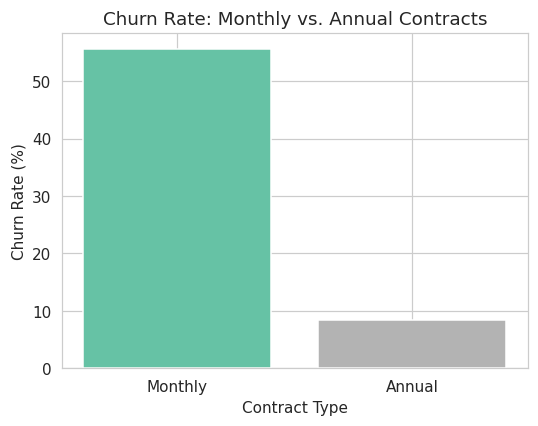

In [26]:
plt.figure(figsize=(5, 4))
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_by_contract)))
plt.bar(churn_by_contract["contract_type"], churn_by_contract["churn_rate_pct"], color=colors)
plt.title("Churn Rate: Monthly vs. Annual Contracts")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

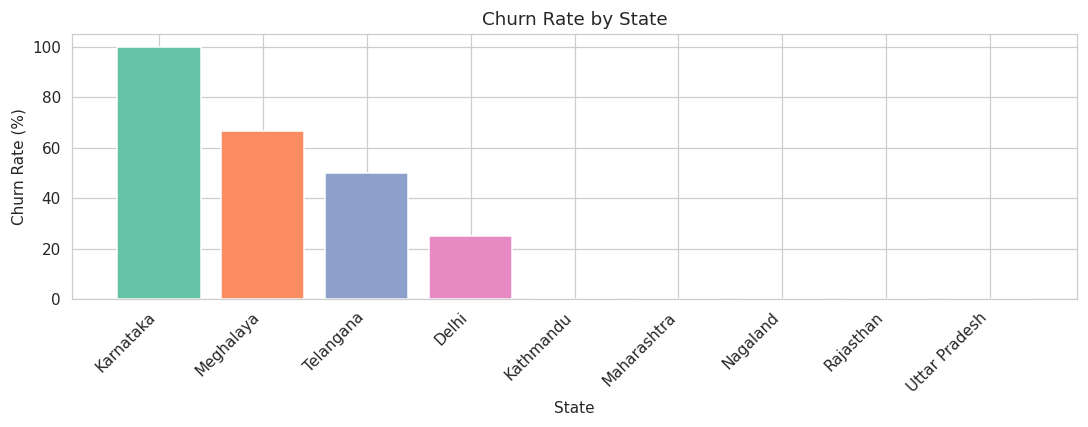

In [27]:
plt.figure(figsize=(10, 4))
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_by_state)))
plt.bar(churn_by_state["state"], churn_by_state["churn_rate_pct"], color=colors)
plt.title("Churn Rate by State")
plt.xlabel("State")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 7.2 Seaborn — correlation & multi-dimensional views

In [28]:
# Ordinal encoding (respects natural business order, not alphabetical) so that
# correlations are directionally meaningful
df_encoded = df[["plan_type", "contract_type", "churn_score", "churn_flag",
                  "churn_risk", "escalation_flag"]].copy()

order_map = {
    "plan_type": ["Basic", "Standard", "Premium"],
    "contract_type": ["Monthly", "Annual"],
    "churn_risk": ["Low", "Medium", "High"],
}
for col, order in order_map.items():
    df_encoded[col] = pd.Categorical(df_encoded[col], categories=order, ordered=True).codes

df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalation_flag
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


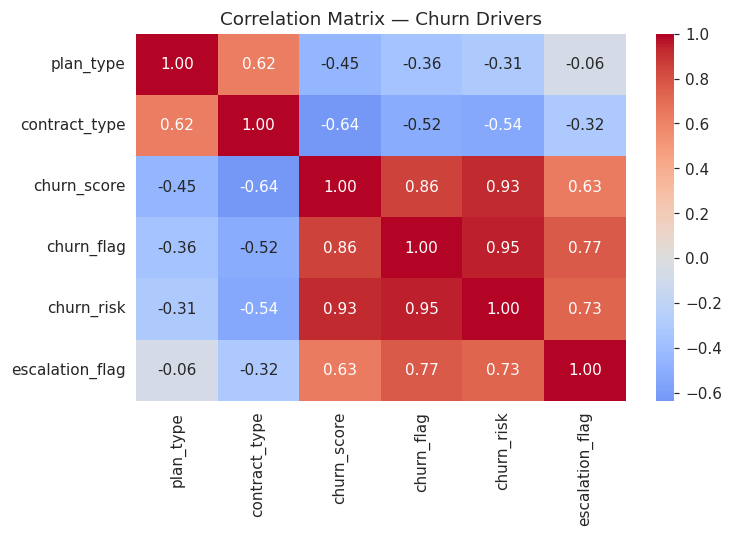

In [29]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_encoded.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix — Churn Drivers")
plt.tight_layout()
plt.show()

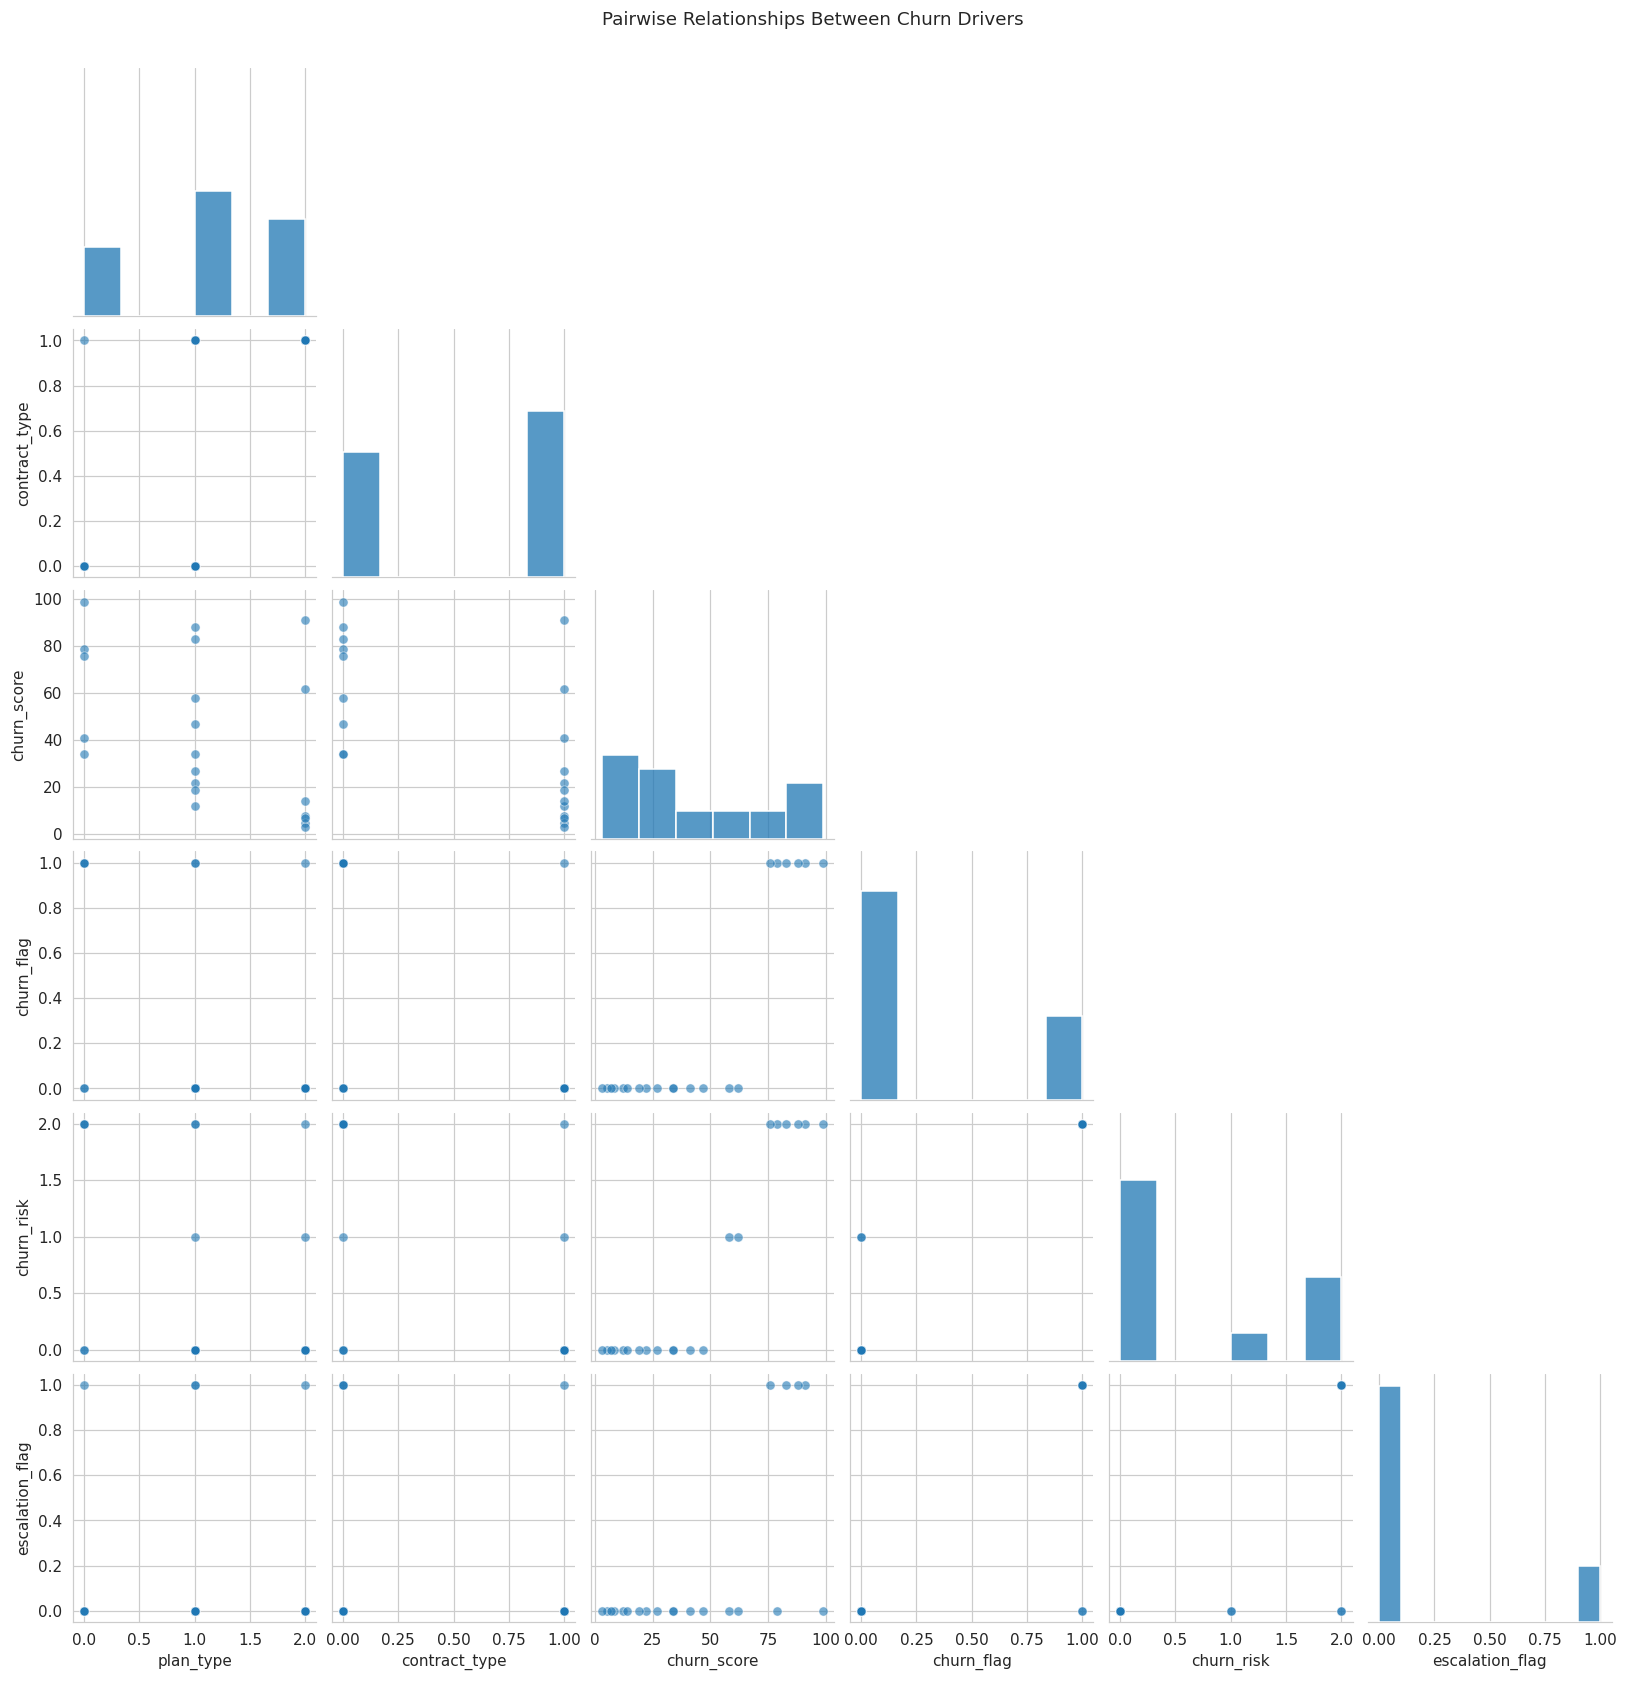

In [30]:
sns.pairplot(df_encoded, corner=True, plot_kws={"alpha": 0.6})
plt.suptitle("Pairwise Relationships Between Churn Drivers", y=1.02)
plt.show()

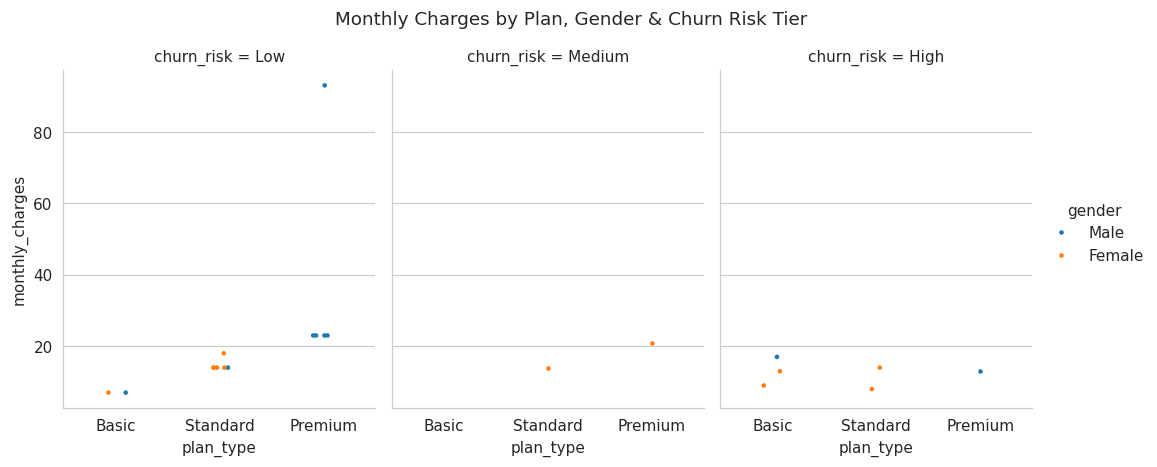

In [31]:
g = sns.catplot(
    data=df, x="plan_type", y="monthly_charges", hue="gender", col="churn_risk",
    kind="strip", height=4, aspect=0.8, order=["Basic", "Standard", "Premium"],
    col_order=["Low", "Medium", "High"], s=9,
)
g.fig.suptitle("Monthly Charges by Plan, Gender & Churn Risk Tier", y=1.05)
plt.show()

### 7.3 Pivot tables

In [32]:
pd.pivot_table(df, index="plan_type", values="churn_flag", aggfunc="mean").mul(100).round(2)

,churn_flag
plan_type,
Basic,60.00
Premium,14.29
Standard,22.22


In [33]:
pd.pivot_table(
    df, index="plan_type",
    values=["monthly_charges", "customerid", "churn_flag"],
    aggfunc={"monthly_charges": "sum", "customerid": "nunique", "churn_flag": "mean"},
).rename(columns={"customerid": "customer_count", "churn_flag": "churn_rate"})

,churn_rate,customer_count,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


## 8. Key Insights & Recommendations

**Headline numbers**


In [34]:
summary = pd.DataFrame({
    "Metric": [
        "Churn Rate", "Retention Rate", "ARPU", "Avg. Customer Tenure (days)",
        "Total Monthly Revenue", "Revenue at Risk", "% Revenue Loss", "CLTV Lost",
        "Escalation Rate", "Correlation (Escalation vs Churn)",
    ],
    "Value": [
        f"{churn_rate:.1f}%", f"{retention_rate:.1f}%", f"{arpu:.2f}", f"{avg_tenure:.0f}",
        f"{total_revenue:.2f}", f"{revenue_at_risk:.2f}", f"{pct_revenue_loss:.1f}%", f"{cltv_lost:.0f}",
        f"{escalation_rate:.1f}%", f"{esc_churn_corr:.2f}",
    ],
})
summary

,Metric,Value
0,Churn Rate,28.6%
1,Retention Rate,71.4%
2,ARPU,18.85
3,Avg. Customer Tenure (days),1505
4,Total Monthly Revenue,395.79
5,Revenue at Risk,73.94
6,% Revenue Loss,18.7%
7,CLTV Lost,2047
8,Escalation Rate,19.0%
9,Correlation (Escalation vs Churn),0.77


**Findings**

- **Overall churn is 28.6%**, with retention at 71.4%.
- **Contract type is the single biggest churn driver**: month-to-month subscribers churn at a dramatically higher
  rate than annual subscribers (see the contract-type chart above), while annual contracts are far stickier.
- **Basic-tier subscribers churn the most** of the three plans, but because Basic has the lowest price point, this
  churn carries comparatively limited revenue impact — the bigger financial risk is concentrated in a small number
  of high-CLTV, high-churn-score customers.
- **Support escalations are strongly correlated with churn.** Customers who escalate a support ticket churn far
  more often than those who don't — support experience is a leading indicator, not just a lagging symptom.
- **Churn is not evenly distributed geographically** — a small number of states account for a disproportionate
  share of cancellations, and are worth a root-cause investigation (pricing, service quality, local competition).
- **Cancellation reasons** cluster around competitive switching, price sensitivity, and content/service
  dissatisfaction — each of which maps to a distinct retention lever.

**Recommendations**

1. **Incentivize the shift from monthly → annual contracts** (e.g. a modest annual-plan discount or loyalty credit)
   — this is the highest-leverage lever in the dataset given the gap in churn rates between the two contract types.
2. **Treat any support escalation as a retention trigger.** Route escalated tickets to a save/retention desk with
   proactive outreach rather than standard support queues.
3. **Prioritize outreach using `churn_risk` × `cltv`.** Build a save-list of "High" risk customers ranked by CLTV
   so retention effort is spent where it protects the most revenue.
4. **Investigate the highest-churn states** for local causes — pricing changes, service quality, or competitor
   activity — before assuming the cause is universal.
5. **Monitor cancellation reasons monthly** as a leading indicator of emerging product, pricing, or competitive
   threats, rather than reviewing them only after a spike in churn.


## 9. Project Summary (Portfolio-Ready)

Built an end-to-end churn analytics pipeline on a relational (SQL) subscription dataset — integrating customer,
subscription, and support data across 20+ engineered KPIs. Quantified a significant churn-rate gap between
monthly and annual contract holders, identified support escalations as a strong leading indicator of churn,
measured revenue and CLTV erosion attributable to churned customers, and translated the findings into a
prioritized, CLTV-weighted retention strategy.

**Tech stack used:** Python (pandas, numpy), SQL (SQLite), matplotlib, seaborn.

---
*Notebook runs end-to-end from the raw SQLite database / Excel source with zero errors.*
